# Stack Overflow Developer Survey Analysis

In [1]:
!pip -q install pandas numpy matplotlib seaborn scipy requests beautifulsoup4 lxml

## 1. Data Loading

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/huyqng1412/stackoverflow_2025_project/main/survey_results_public.csv"

df = pd.read_csv(url, low_memory=False)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", len(df.columns))
print("\nFirst 10 columns:")
print(df.columns[:10].tolist())

Dataset loaded successfully
Shape: (2, 1)
Columns: 1

First 10 columns:
['version https://git-lfs.github.com/spec/v1']


In [3]:
import requests
import zipfile
import io
import os

url = "https://github.com/isachenko-andrii/Stack-overflow-software-developer-survey-analysis/raw/refs/heads/main/data/raw/stack-overflow-developer-survey-2025.zip"

response = requests.get(url, timeout=180)

print("Status:", response.status_code)
print("Downloaded:", round(len(response.content) / (1024 * 1024), 2), "MB")

response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("\nFiles in ZIP:")
    for name in z.namelist():
        print(name)

Status: 200
Downloaded: 16.13 MB

Files in ZIP:
2025_Developer_Survey_Tool.pdf
survey_results_public.csv
survey_results_schema.csv


In [4]:
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("stackoverflow_2025")

df = pd.read_csv(
    "stackoverflow_2025/survey_results_public.csv",
    low_memory=False
)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Number of columns:", len(df.columns))
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully
Shape: (49191, 172)
Number of columns: 172

Columns:
['ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment', 'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode', 'LearnCodeAI', 'AILearnHow', 'YearsCode', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'PurchaseInfluence', 'TechEndorseIntro', 'TechEndorse_1', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9', 'TechEndorse_13', 'TechEndorse_13_TEXT', 'TechOppose_1', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5', 'TechOppose_7', 'TechOppose_9', 'TechOppose_11', 'TechOppose_13', 'TechOppose_16', 'TechOppose_15', 'TechOppose_15_TEXT', 'Industry', 'JobSatPoints_1', 'JobSatPoints_2', 'JobSatPoints_3', 'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10', 'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14', 'JobSatPoints_15', 'JobSatPoints_16', 

## 2. Data Preparation

In [5]:
project_df = df[
    [
        "ConvertedCompYearly",
        "Country",
        "DevType",
        "YearsCode",
        "LanguageHaveWorkedWith",
        "DatabaseHaveWorkedWith",
        "PlatformHaveWorkedWith"
    ]
].copy()

project_df.columns = [
    "Salary_USD",
    "Country",
    "Developer_Type",
    "Years_Code",
    "Languages",
    "Databases",
    "Cloud_Platforms"
]

print("Project dataset shape:", project_df.shape)
print("\nMissing values:")
print(project_df.isnull().sum())
print("\nPreview:")
display(project_df.head())

Project dataset shape: (49191, 7)

Missing values:
Salary_USD         25244
Country            13754
Developer_Type      5511
Years_Code          6149
Languages          17520
Databases          23641
Cloud_Platforms    24933
dtype: int64

Preview:


,Salary_USD,Country,Developer_Type,Years_Code,Languages,Databases,Cloud_Platforms
0,61256.0,Ukraine,"Developer, mobile",14.0,Bash/Shell (all shells);Dart;SQL,Cloud Firestore;PostgreSQL,Amazon Web Services (AWS);Cloudflare;Firebase;...
1,104413.0,Netherlands,"Developer, back-end",10.0,Java,Dynamodb;MongoDB,Amazon Web Services (AWS);Datadog;Docker;Homeb...
2,53061.0,Ukraine,"Developer, front-end",12.0,Dart;HTML/CSS;JavaScript;TypeScript,MongoDB;MySQL;PostgreSQL,Datadog;Firebase;npm;pnpm
3,36197.0,Ukraine,"Developer, back-end",5.0,Java;Kotlin;SQL,NaN,Amazon Web Services (AWS);Google Cloud
4,60000.0,Ukraine,Engineering manager,22.0,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,Elasticsearch;Microsoft SQL Server;MySQL;Oracl...,Amazon Web Services (AWS);APT;Docker;Make;Mave...


In [6]:
project_df["Salary_USD"] = pd.to_numeric(
    project_df["Salary_USD"],
    errors="coerce"
)

project_df["Years_Code"] = pd.to_numeric(
    project_df["Years_Code"],
    errors="coerce"
)

salary_df = project_df[
    project_df["Salary_USD"].notna() &
    (project_df["Salary_USD"] > 0) &
    (project_df["Salary_USD"] < 1000000)
].copy()

salary_df.reset_index(drop=True, inplace=True)

print("Salary dataset shape:", salary_df.shape)
print("\nSalary statistics:")
print(salary_df["Salary_USD"].describe())

Salary dataset shape: (23893, 7)

Salary statistics:
count     23893.000000
mean      91298.927426
std       83338.668807
min           1.000000
25%       38000.000000
50%       75000.000000
75%      120000.000000
max      988273.000000
Name: Salary_USD, dtype: float64


## 3. Descriptive Statistics of Salary

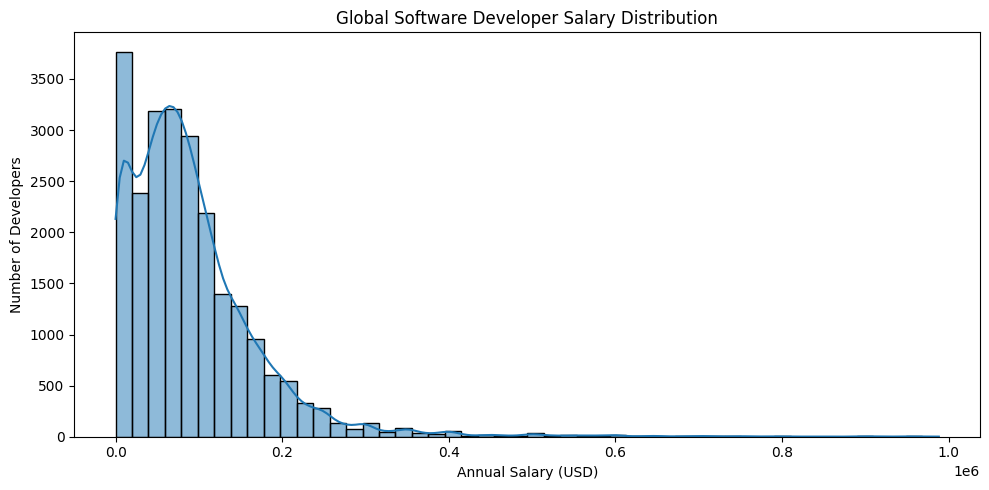

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    salary_df["Salary_USD"],
    bins=50,
    kde=True
)

plt.title("Global Software Developer Salary Distribution")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Number of Developers")

plt.tight_layout()
plt.show()

In [8]:
salary_stats = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "25th Percentile",
        "75th Percentile",
        "Maximum",
        "Skewness"
    ],
    "Value": [
        salary_df["Salary_USD"].count(),
        salary_df["Salary_USD"].mean(),
        salary_df["Salary_USD"].median(),
        salary_df["Salary_USD"].std(),
        salary_df["Salary_USD"].min(),
        salary_df["Salary_USD"].quantile(0.25),
        salary_df["Salary_USD"].quantile(0.75),
        salary_df["Salary_USD"].max(),
        salary_df["Salary_USD"].skew()
    ]
})

display(salary_stats)

,Statistic,Value
0,Count,23893.000000
1,Mean,91298.927426
2,Median,75000.000000
3,Standard Deviation,83338.668807
4,Minimum,1.000000
5,25th Percentile,38000.000000
6,75th Percentile,120000.000000
7,Maximum,988273.000000
8,Skewness,2.829078


### Country-wise Salary Analysis

In [9]:
country_salary = (
    salary_df
    .dropna(subset=["Country"])
    .groupby("Country")["Salary_USD"]
    .agg(
        Developers="count",
        Mean_Salary="mean",
        Median_Salary="median",
        Std_Deviation="std"
    )
    .sort_values("Median_Salary", ascending=False)
)

country_salary_filtered = country_salary[
    country_salary["Developers"] >= 50
]

display(country_salary_filtered.head(20))

,Developers,Mean_Salary,Median_Salary,Std_Deviation
Country,,,,
United States of America,5222,163880.280352,150000.0,105330.214892
Switzerland,417,148679.800959,142592.0,84737.885925
Israel,177,131723.762712,141188.0,72553.201456
Ireland,154,121326.818182,116015.0,58124.873019
Denmark,229,99702.192140,98600.0,59067.749523
Australia,568,109278.348592,97514.0,71955.036865
United Kingdom of Great Britain and Northern Ireland,1481,106704.951384,94087.0,68098.011815
Singapore,64,131430.187500,92563.0,114791.486106
Norway,184,99256.809783,88945.0,75407.149887


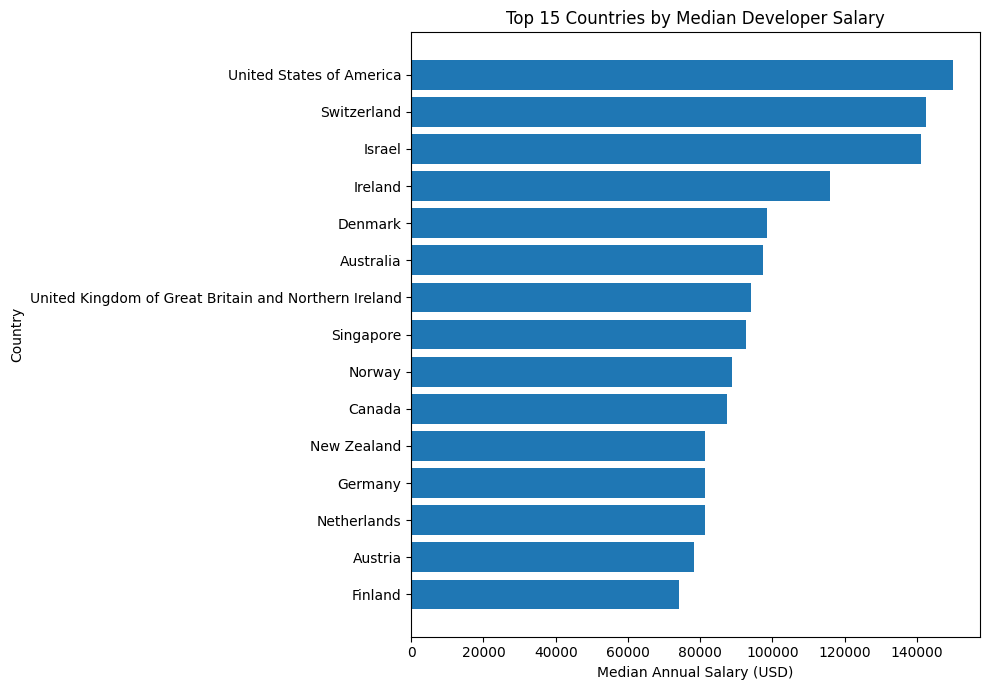

In [10]:
top_countries = country_salary_filtered.head(15).sort_values(
    "Median_Salary"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_countries.index,
    top_countries["Median_Salary"]
)

plt.title("Top 15 Countries by Median Developer Salary")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

## 4. Correlation Between Years of Experience and Salary

In [11]:
experience_df = salary_df.dropna(
    subset=["Years_Code"]
).copy()

experience_df["Years_Code"] = pd.to_numeric(
    experience_df["Years_Code"],
    errors="coerce"
)

experience_df = experience_df[
    (experience_df["Years_Code"] >= 0) &
    (experience_df["Years_Code"] <= 50)
]

experience_salary = (
    experience_df
    .groupby("Years_Code")["Salary_USD"]
    .agg(
        Developers="count",
        Mean_Salary="mean",
        Median_Salary="median"
    )
)

display(experience_salary.head(15))

,Developers,Mean_Salary,Median_Salary
Years_Code,,,
1.0,188,24626.989362,5782.0
2.0,233,28071.334764,6961.0
3.0,431,25876.531323,11624.0
4.0,567,32562.617284,15082.0
5.0,879,40356.308305,26000.0
6.0,887,45666.019166,33403.0
7.0,903,53345.569214,40935.0
8.0,1113,57659.270440,45246.0
9.0,802,68301.997506,53218.0


In [12]:
correlation = experience_df[
    ["Years_Code", "Salary_USD"]
].corr()

print("Correlation Matrix:")
display(correlation)

r = correlation.loc[
    "Years_Code",
    "Salary_USD"
]

print(f"Pearson correlation coefficient: {r:.4f}")

Correlation Matrix:


,Years_Code,Salary_USD
Years_Code,1.000000,0.340043
Salary_USD,0.340043,1.000000


Pearson correlation coefficient: 0.3400


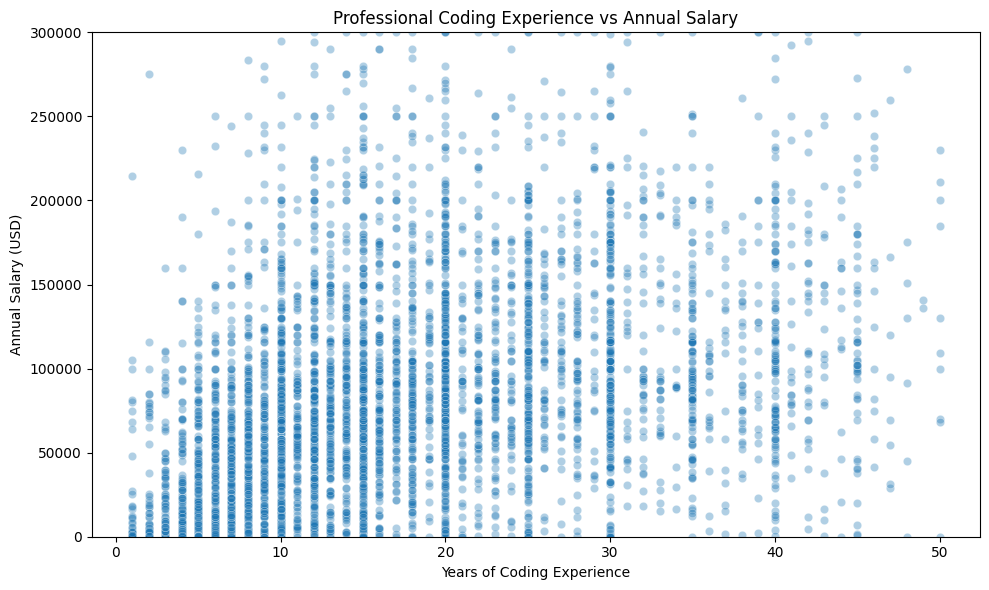

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=experience_df.sample(
        min(5000, len(experience_df)),
        random_state=42
    ),
    x="Years_Code",
    y="Salary_USD",
    alpha=0.35
)

plt.ylim(0, 300000)
plt.title("Professional Coding Experience vs Annual Salary")
plt.xlabel("Years of Coding Experience")
plt.ylabel("Annual Salary (USD)")

plt.tight_layout()
plt.show()

## 5. Sampling and Sampling Distributions

In [14]:
population = salary_df["Salary_USD"].dropna().reset_index(drop=True)

sample_size = 500

random_sample = population.sample(
    n=sample_size,
    random_state=42
)

print("Population size:", len(population))
print("Sample size:", len(random_sample))
print("Population mean:", round(population.mean(), 2))
print("Sample mean:", round(random_sample.mean(), 2))

Population size: 23893
Sample size: 500
Population mean: 91298.93
Sample mean: 96049.67


In [15]:
stratified_population = salary_df.dropna(
    subset=["Country"]
).copy()

country_counts = stratified_population["Country"].value_counts()

valid_countries = country_counts[
    country_counts >= 50
].index

stratified_population = stratified_population[
    stratified_population["Country"].isin(valid_countries)
]

n = 500

stratified_sample = (
    stratified_population
    .groupby("Country", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=max(
                1,
                round(
                    len(x) /
                    len(stratified_population) *
                    n
                )
            ),
            random_state=42
        )
    )
)

stratified_sample = stratified_sample.sample(
    n=min(n, len(stratified_sample)),
    random_state=42
)

print("Stratified population:", len(stratified_population))
print("Stratified sample:", len(stratified_sample))
print("Stratified sample mean:", round(
    stratified_sample["Salary_USD"].mean(), 2
))

Stratified population: 22755
Stratified sample: 500
Stratified sample mean: 92588.96


/tmp/ipykernel_1491/1068342904.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


### Central Limit Theorem Demonstration

In [16]:
import numpy as np
sample_sizes = [10, 30, 50, 100, 500]
simulations = 1000

sampling_distributions = {}

for n in sample_sizes:
    sample_means = []

    for _ in range(simulations):
        sample = population.sample(
            n=n,
            replace=False
        )
        sample_means.append(sample.mean())

    sampling_distributions[n] = np.array(sample_means)

print("Sampling distributions generated successfully")

for n in sample_sizes:
    print(
        f"n={n}: "
        f"mean={sampling_distributions[n].mean():.2f}, "
        f"std={sampling_distributions[n].std():.2f}"
    )

Sampling distributions generated successfully
n=10: mean=90967.42, std=25446.18
n=30: mean=91456.65, std=15884.88
n=50: mean=90739.57, std=11492.87
n=100: mean=91069.68, std=8426.11
n=500: mean=91380.50, std=3565.27


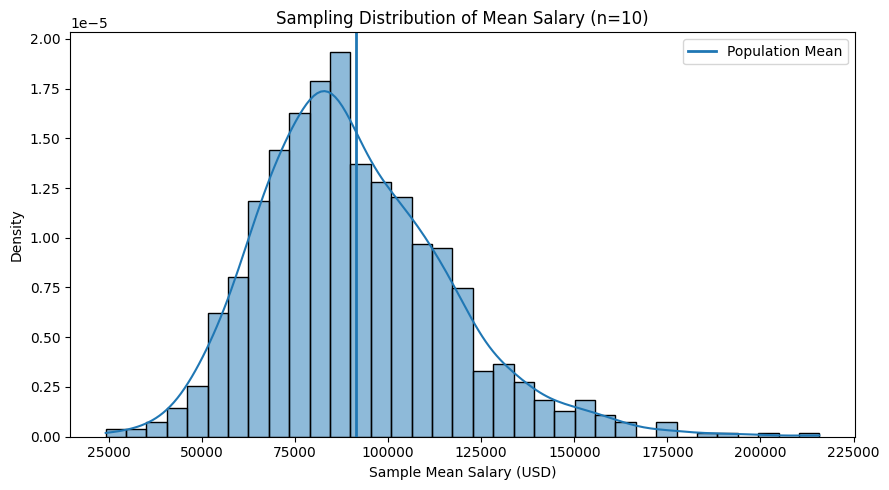

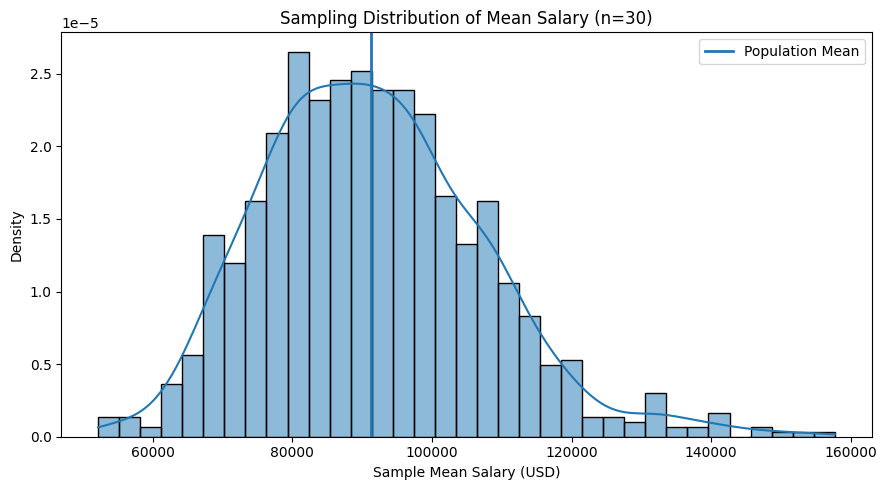

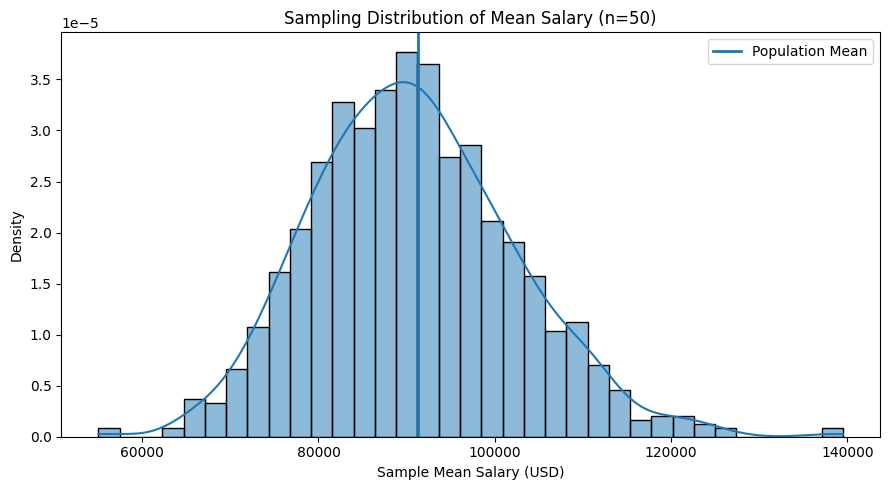

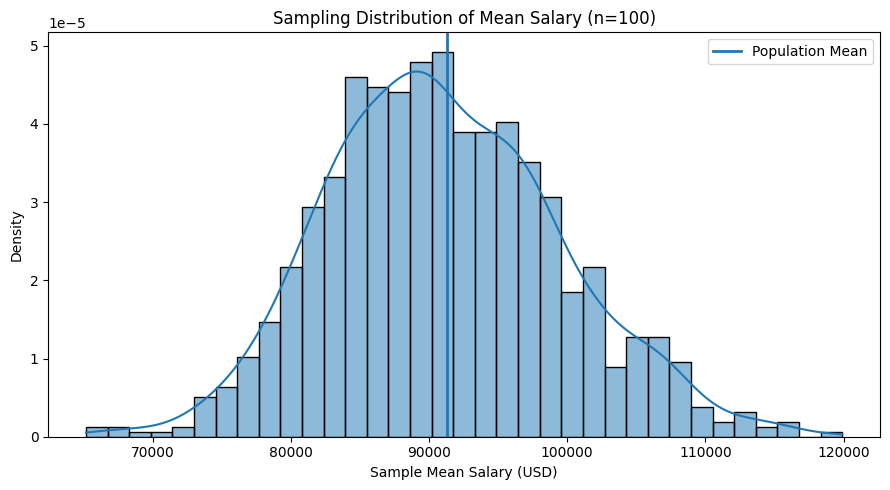

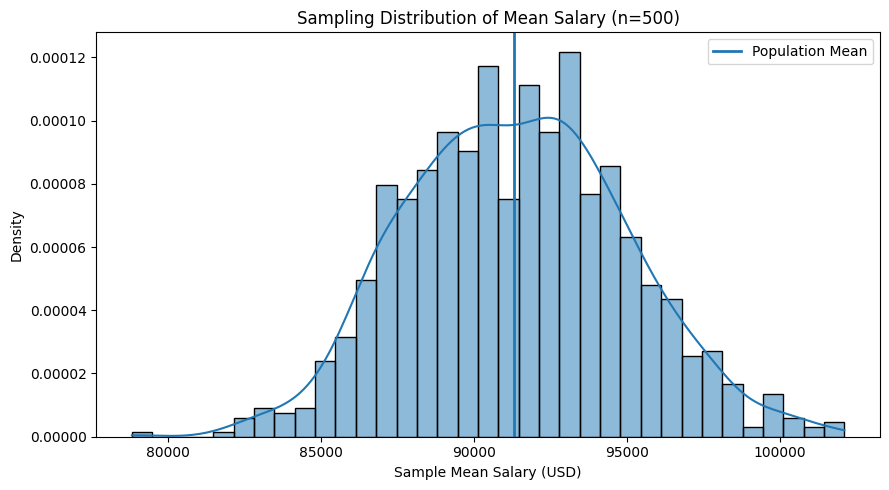

In [17]:
for n in sample_sizes:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        sampling_distributions[n],
        bins=35,
        kde=True,
        stat="density"
    )

    plt.axvline(
        population.mean(),
        linewidth=2,
        label="Population Mean"
    )

    plt.title(
        f"Sampling Distribution of Mean Salary (n={n})"
    )
    plt.xlabel("Sample Mean Salary (USD)")
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.show()

## 6. Confidence Interval for Mean Salary

In [18]:
population_mean = population.mean()
population_std = population.std()

clt_results = []

for n in sample_sizes:
    sample_means = sampling_distributions[n]

    empirical_mean = sample_means.mean()
    empirical_se = sample_means.std(ddof=1)
    theoretical_se = population_std / np.sqrt(n)

    clt_results.append([
        n,
        empirical_mean,
        empirical_se,
        theoretical_se,
        abs(empirical_se - theoretical_se)
    ])

clt_results = pd.DataFrame(
    clt_results,
    columns=[
        "Sample_Size",
        "Mean_of_Sample_Means",
        "Empirical_SE",
        "Theoretical_SE",
        "SE_Difference"
    ]
)

display(clt_results.round(2))

,Sample_Size,Mean_of_Sample_Means,Empirical_SE,Theoretical_SE,SE_Difference
0,10,90967.42,25458.91,26354.00,895.09
1,30,91456.65,15892.83,15215.49,677.34
2,50,90739.57,11498.62,11785.87,287.24
3,100,91069.68,8430.33,8333.87,96.46
4,500,91380.50,3567.06,3727.02,159.96


In [22]:
from scipy import stats
sample = population.sample(
    n=500,
    random_state=42
)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)
n = len(sample)

confidence_level = 0.95
degrees_of_freedom = n - 1

standard_error = sample_std / np.sqrt(n)

t_critical = stats.t.ppf(
    1 - (1 - confidence_level) / 2,
    degrees_of_freedom
)

margin_of_error = t_critical * standard_error

lower_bound = sample_mean - margin_of_error
upper_bound = sample_mean + margin_of_error

print("Sample Mean:", round(sample_mean, 2))
print("Sample Standard Deviation:", round(sample_std, 2))
print("Standard Error:", round(standard_error, 2))
print("Margin of Error:", round(margin_of_error, 2))
print("95% Confidence Interval:")
print(
    f"({lower_bound:.2f}, {upper_bound:.2f})"
)


Sample Mean: 96049.67
Sample Standard Deviation: 81386.3
Standard Error: 3639.71
Margin of Error: 7151.04
95% Confidence Interval:
(88898.63, 103200.71)


## 7. Hypothesis Testing: India vs. USA Salaries

In [23]:
india = salary_df[
    salary_df["Country"] == "India"
]["Salary_USD"].dropna()

usa = salary_df[
    salary_df["Country"] == "United States of America"
]["Salary_USD"].dropna()

sample_size = 500

india_sample = india.sample(
    n=min(sample_size, len(india)),
    random_state=42
)

usa_sample = usa.sample(
    n=min(sample_size, len(usa)),
    random_state=42
)

t_statistic, p_value = stats.ttest_ind(
    india_sample,
    usa_sample,
    equal_var=False
)

print("India sample size:", len(india_sample))
print("USA sample size:", len(usa_sample))
print("India sample mean:", round(india_sample.mean(), 2))
print("USA sample mean:", round(usa_sample.mean(), 2))
print("t-statistic:", round(t_statistic, 4))
print("p-value:", p_value)

India sample size: 500
USA sample size: 500
India sample mean: 29601.46
USA sample mean: 165072.8
t-statistic: -26.728
p-value: 1.0338014372408478e-105


In [24]:
alpha = 0.05

if p_value < alpha:
    conclusion = "Reject H0"
else:
    conclusion = "Fail to reject H0"

print("Significance level:", alpha)
print("P-value:", f"{p_value:.6e}")
print("Decision:", conclusion)

if p_value < alpha:
    print("There is statistically significant evidence of a difference in mean salaries between India and the United States.")
else:
    print("There is insufficient statistical evidence of a difference in mean salaries between India and the United States.")

Significance level: 0.05
P-value: 1.033801e-105
Decision: Reject H0
There is statistically significant evidence of a difference in mean salaries between India and the United States.


## 8. Programming Language Popularity and Demand

In [25]:
language_data = df[
    ["LanguageHaveWorkedWith"]
].dropna().copy()

language_data["Language"] = language_data[
    "LanguageHaveWorkedWith"
].str.split(";")

language_data = language_data.explode("Language")

language_data["Language"] = language_data[
    "Language"
].str.strip()

language_counts = (
    language_data["Language"]
    .value_counts()
    .rename("Developers")
    .to_frame()
)

language_counts["Probability"] = (
    language_counts["Developers"] /
    len(df[df["LanguageHaveWorkedWith"].notna()])
)

language_counts["Percentage"] = (
    language_counts["Probability"] * 100
)

top_languages = language_counts.head(15)

display(top_languages)

,Developers,Probability,Percentage
Language,,,
JavaScript,21005,0.663225,66.322503
HTML/CSS,19698,0.621957,62.195700
SQL,18633,0.588330,58.833002
Python,18410,0.581289,58.128888
Bash/Shell (all shells),15503,0.489501,48.950144
TypeScript,13859,0.437593,43.759275
Java,9358,0.295475,29.547536
C#,8852,0.279499,27.949859
C++,7485,0.236336,23.633608


### Binomial Probability for Python Demand

In [26]:
from scipy.stats import binom

p_python = language_counts.loc["Python", "Probability"]
n = 20

k_values = np.arange(0, n + 1)

binomial_probabilities = binom.pmf(
    k_values,
    n,
    p_python
)

binomial_df = pd.DataFrame({
    "Python_Developers_in_Sample": k_values,
    "Probability": binomial_probabilities
})

display(binomial_df)

prob_at_least_10 = 1 - binom.cdf(
    9,
    n,
    p_python
)

print("Estimated probability of Python demand:", round(p_python, 4))
print(
    "Probability of at least 10 Python developers "
    "in a sample of 20:",
    round(prob_at_least_10, 4)
)

,Python_Developers_in_Sample,Probability
0,0,2.743405e-08
1,1,7.617237e-07
2,2,1.004613e-05
3,3,8.368110e-05
4,4,4.937349e-04
5,5,2.193417e-03
6,6,7.612702e-03
7,7,2.113715e-02
8,8,4.768450e-02
9,9,8.826600e-02


Estimated probability of Python demand: 0.5813
Probability of at least 10 Python developers in a sample of 20: 0.8325


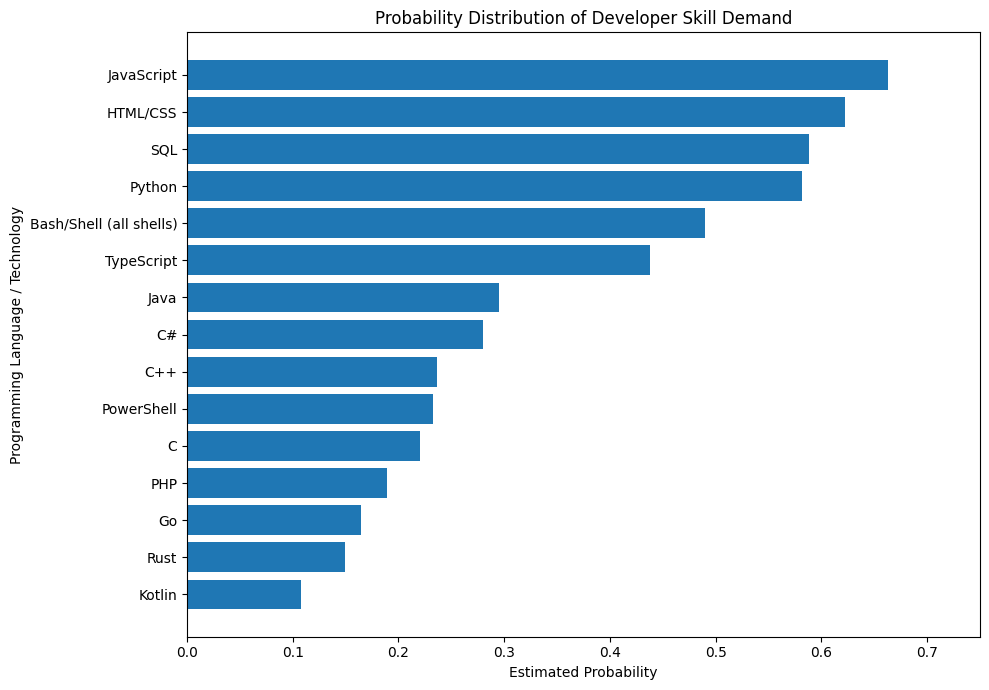

In [27]:
top_skill_data = language_counts.head(15).sort_values(
    "Probability"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_skill_data.index,
    top_skill_data["Probability"]
)

plt.title("Probability Distribution of Developer Skill Demand")
plt.xlabel("Estimated Probability")
plt.ylabel("Programming Language / Technology")

plt.xlim(0, 0.75)
plt.tight_layout()
plt.show()

## 9. Web Scraping for Survey Insights

In [28]:
import requests
from bs4 import BeautifulSoup

scrape_url = "https://survey.stackoverflow.co/2025/"

scrape_response = requests.get(
    scrape_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=60
)

print("Status:", scrape_response.status_code)

scrape_response.raise_for_status()

soup = BeautifulSoup(
    scrape_response.text,
    "html.parser"
)

title = soup.title.get_text(strip=True) if soup.title else "No title found"

headings = [
    h.get_text(" ", strip=True)
    for h in soup.find_all(["h1", "h2", "h3"])
]

print("Page title:", title)
print("Number of headings scraped:", len(headings))
print("\nFirst 15 headings:")

for heading in headings[:15]:
    print("-", heading)

Status: 200
Page title: 2025 Stack Overflow Developer Survey
Number of headings scraped: 26

First 15 headings:
- Visual Studio and Visual Studio Code both maintained their top spots for developer environments used for the fourth year
- One in four developers are happy at their current job
- Younger developers want developer content with social or interactive formats
- uv is the most admired SO tag technology this year
- Privacy, pricing and better alternatives are top reasons developers turn their back on a technology
- Python adoption grew in 2025
- More than one third of respondents use AI-enabled tools to learn AI this year
- 84% of respondents are using AI tools this year
- 66% of developers are frustrated with AI solutions that are almost right
- Respondents learning to code use YouTube for community more than professional developers
- Positive sentiment to AI tools has decreased in 2025
- More developers actively distrust the accuracy of AI tools than trust it
- A majority of de

In [29]:
scraped_data = pd.DataFrame({
    "Topic": headings,
    "Source_URL": scrape_url
})

scraped_data = scraped_data.drop_duplicates(
    subset=["Topic"]
).reset_index(drop=True)

print("Scraped records:", len(scraped_data))
display(scraped_data.head(10))


Scraped records: 26


,Topic,Source_URL
0,Visual Studio and Visual Studio Code both main...,https://survey.stackoverflow.co/2025/
1,One in four developers are happy at their curr...,https://survey.stackoverflow.co/2025/
2,Younger developers want developer content with...,https://survey.stackoverflow.co/2025/
3,uv is the most admired SO tag technology this ...,https://survey.stackoverflow.co/2025/
4,"Privacy, pricing and better alternatives are t...",https://survey.stackoverflow.co/2025/
5,Python adoption grew in 2025,https://survey.stackoverflow.co/2025/
6,More than one third of respondents use AI-enab...,https://survey.stackoverflow.co/2025/
7,84% of respondents are using AI tools this year,https://survey.stackoverflow.co/2025/
8,66% of developers are frustrated with AI solut...,https://survey.stackoverflow.co/2025/
9,Respondents learning to code use YouTube for c...,https://survey.stackoverflow.co/2025/


## 10. Python Developer Proportion Analysis

In [30]:
python_users = language_data[
    language_data["Language"] == "Python"
]

python_user_ids = set(
    df.index[df["LanguageHaveWorkedWith"].notna()]
)

python_developer_ids = set(
    python_users.index
)

python_rate = len(
    set(python_user_ids).intersection(python_developer_ids)
) / len(python_user_ids)

n = 500
simulations = 1000

sample_proportions = []

for _ in range(simulations):
    sample = np.random.binomial(
        1,
        python_rate,
        n
    )

    sample_proportions.append(
        sample.mean()
    )

sample_proportions = np.array(
    sample_proportions
)

theoretical_se = np.sqrt(
    python_rate * (1 - python_rate) / n
)

print("Estimated Python proportion:", round(python_rate, 4))
print("Mean of sample proportions:", round(
    sample_proportions.mean(), 4
))
print("Empirical standard error:", round(
    sample_proportions.std(ddof=1), 4
))
print("Theoretical standard error:", round(
    theoretical_se, 4
))

Estimated Python proportion: 0.5813
Mean of sample proportions: 0.582
Empirical standard error: 0.0225
Theoretical standard error: 0.0221


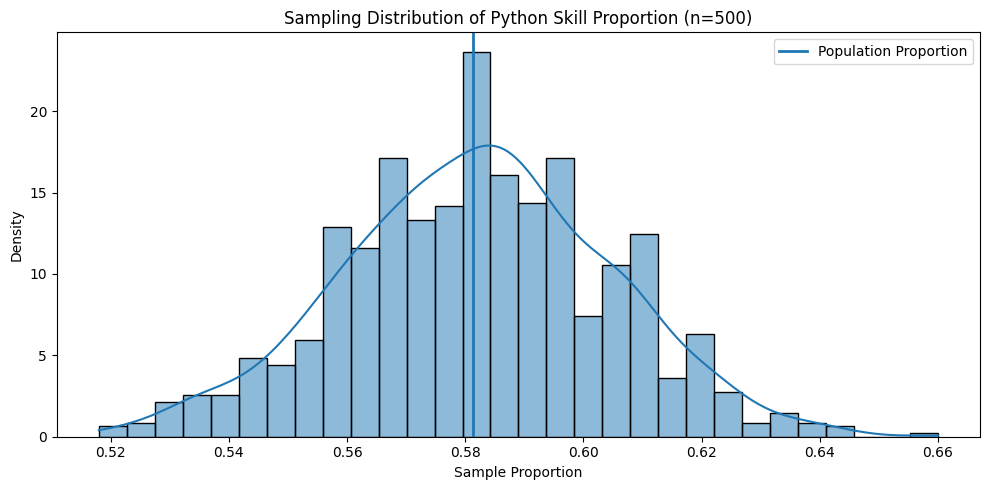

In [31]:
plt.figure(figsize=(10, 5))

sns.histplot(
    sample_proportions,
    bins=30,
    kde=True,
    stat="density"
)

plt.axvline(
    python_rate,
    linewidth=2,
    label="Population Proportion"
)

plt.title(
    "Sampling Distribution of Python Skill Proportion (n=500)"
)
plt.xlabel("Sample Proportion")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
from scipy import stats

x = round(python_rate * len(python_user_ids))
n = len(python_user_ids)

sample_proportion = x / n

z_critical = stats.norm.ppf(0.975)

proportion_se = np.sqrt(
    sample_proportion * (1 - sample_proportion) / n
)

margin_of_error = z_critical * proportion_se

lower = sample_proportion - margin_of_error
upper = sample_proportion + margin_of_error

print("Python skill proportion:", round(sample_proportion, 4))
print("Sample size:", n)
print("Standard Error:", round(proportion_se, 6))
print("Margin of Error:", round(margin_of_error, 6))
print("95% Confidence Interval:")
print(f"({lower:.4f}, {upper:.4f})")

Python skill proportion: 0.5813
Sample size: 31671
Standard Error: 0.002772
Margin of Error: 0.005433
95% Confidence Interval:
(0.5759, 0.5867)


## 11. Comparison of Sampling Methods

In [33]:
python_mask = df["LanguageHaveWorkedWith"].fillna("").str.contains(
    r"(^|;)Python(;|$)",
    regex=True
)

python_count = python_mask.sum()
python_total = df["LanguageHaveWorkedWith"].notna().sum()

python_rate = python_count / python_total

print("Developers reporting Python:", python_count)
print("Developers with language data:", python_total)
print("Estimated Python skill probability:", round(python_rate, 4))
print("Estimated percentage:", round(python_rate * 100, 2), "%")

Developers reporting Python: 18410
Developers with language data: 31671
Estimated Python skill probability: 0.5813
Estimated percentage: 58.13 %


/tmp/ipykernel_1491/4268220249.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  python_mask = df["LanguageHaveWorkedWith"].fillna("").str.contains(


In [34]:
sampling_interval = len(population) // sample_size
start = np.random.randint(0, sampling_interval)
systematic_indices = np.arange(start, len(population), sampling_interval)
systematic_sample = population.iloc[systematic_indices]

print("Systematic sample size:", len(systematic_sample))
print("Systematic sample mean:", round(systematic_sample.mean(), 2))

Systematic sample size: 508
Systematic sample mean: 96903.67


In [35]:
sampling_comparison = pd.DataFrame({
    "Sampling_Method": [
        "Population",
        "Simple Random Sampling",
        "Systematic Sampling",
        "Stratified Sampling"
    ],
    "Sample_Size": [
        len(population),
        len(random_sample),
        len(systematic_sample),
        len(stratified_sample)
    ],
    "Mean_Salary": [
        population.mean(),
        random_sample.mean(),
        systematic_sample.mean(),
        stratified_sample["Salary_USD"].mean()
    ]
})

sampling_comparison["Absolute_Error"] = (
    sampling_comparison["Mean_Salary"] -
    population.mean()
).abs()

display(
    sampling_comparison.round(2)
)

,Sampling_Method,Sample_Size,Mean_Salary,Absolute_Error
0,Population,23893,91298.93,0.00
1,Simple Random Sampling,500,96049.67,4750.74
2,Systematic Sampling,508,96903.67,5604.74
3,Stratified Sampling,500,92588.96,1290.04


## 12. Central Limit Theorem Summary

In [36]:
clt_summary = clt_results.copy()

clt_summary["Relative_SE_Error_%"] = (
    abs(
        clt_summary["Empirical_SE"] -
        clt_summary["Theoretical_SE"]
    ) /
    clt_summary["Theoretical_SE"]
) * 100

display(
    clt_summary.round(2)
)

,Sample_Size,Mean_of_Sample_Means,Empirical_SE,Theoretical_SE,SE_Difference,Relative_SE_Error_%
0,10,90967.42,25458.91,26354.00,895.09,3.40
1,30,91456.65,15892.83,15215.49,677.34,4.45
2,50,90739.57,11498.62,11785.87,287.24,2.44
3,100,91069.68,8430.33,8333.87,96.46,1.16
4,500,91380.50,3567.06,3727.02,159.96,4.29


## 13. Top Programming Skills by Salary

In [37]:
top_languages_list = language_counts.head(10).index.tolist()

skill_salary = []

for language in top_languages_list:
    mask = salary_df["Languages"].fillna("").str.contains(
        rf"(^|;){language}(;|$)",
        regex=True
    )

    salaries = salary_df.loc[
        mask,
        "Salary_USD"
    ]

    skill_salary.append([
        language,
        len(salaries),
        salaries.mean(),
        salaries.median()
    ])

skill_salary = pd.DataFrame(
    skill_salary,
    columns=[
        "Language",
        "Developers",
        "Mean_Salary",
        "Median_Salary"
    ]
)

skill_salary = skill_salary.sort_values(
    "Median_Salary",
    ascending=False
)

display(skill_salary.round(2))

/tmp/ipykernel_1491/3879909391.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = salary_df["Languages"].fillna("").str.contains(


,Language,Developers,Mean_Salary,Median_Salary
9,PowerShell,5329,91354.27,80984.0
5,TypeScript,10317,94566.08,79141.0
7,C#,6384,90959.78,78488.5
3,Python,12707,96088.08,76570.0
2,SQL,13522,92169.72,76239.0
0,JavaScript,14849,90740.47,75294.0
6,Java,6270,93338.93,75000.0
1,HTML/CSS,13759,88497.34,73785.0
8,C++,4083,93018.79,72815.0
4,Bash/Shell (all shells),0,NaN,NaN


In [38]:
skill_salary = []

for language in top_languages_list:
    mask = salary_df["Languages"].fillna("").apply(
        lambda x: language in [item.strip() for item in x.split(";")]
    )

    salaries = salary_df.loc[mask, "Salary_USD"].dropna()

    skill_salary.append([
        language,
        len(salaries),
        salaries.mean(),
        salaries.median()
    ])

skill_salary = pd.DataFrame(
    skill_salary,
    columns=[
        "Language",
        "Developers",
        "Mean_Salary",
        "Median_Salary"
    ]
)

skill_salary = skill_salary.sort_values(
    "Median_Salary",
    ascending=False
)

display(skill_salary.round(2))

,Language,Developers,Mean_Salary,Median_Salary
4,Bash/Shell (all shells),11083,100645.60,83507.0
9,PowerShell,5329,91354.27,80984.0
5,TypeScript,10317,94566.08,79141.0
7,C#,6384,90959.78,78488.5
3,Python,12707,96088.08,76570.0
2,SQL,13522,92169.72,76239.0
0,JavaScript,14849,90740.47,75294.0
6,Java,6270,93338.93,75000.0
8,C++,4593,94402.87,74000.0
1,HTML/CSS,13759,88497.34,73785.0


In [39]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# 1. LAB 5: One-Sample Z-Test & t-Test + 95% Confidence Intervals
# -------------------------------------------------------------------
salary_clean = salary_df["Salary_USD"].dropna()
sample_mean = salary_clean.mean()
sample_std = salary_clean.std()
n = len(salary_clean)

# 95% Confidence Interval for Population Mean Salary
ci_95 = stats.t.interval(0.95, df=n-1, loc=sample_mean, scale=sample_std/np.sqrt(n))
print(f"95% Confidence Interval for Salary: ${ci_95[0]:,.2f} to ${ci_95[1]:,.2f}")

# One-Sample t-Test (Hypothesized mean salary = $90,000)
pop_mean_hypo = 90000
t_stat, p_val_t = stats.ttest_1samp(salary_clean, pop_mean_hypo)
print(f"One-Sample t-test: t = {t_stat:.4f}, p-value = {p_val_t:.4e}")

# One-Sample Z-Test (using sample std as population std proxy due to large n)
z_stat = (sample_mean - pop_mean_hypo) / (sample_std / np.sqrt(n))
p_val_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print(f"One-Sample Z-test: Z = {z_stat:.4f}, p-value = {p_val_z:.4e}\n")


# -------------------------------------------------------------------
# 2. PRACTICAL 6 PART B: Covariance & Correlation Analysis
# -------------------------------------------------------------------
corr_df = salary_df[["Years_Code", "Salary_USD"]].dropna()

cov_matrix = np.cov(corr_df["Years_Code"], corr_df["Salary_USD"])
cov_val = cov_matrix[0, 1]

pearson_r, p_val_pearson = stats.pearsonr(corr_df["Years_Code"], corr_df["Salary_USD"])
spearman_rho, p_val_spearman = stats.spearmanr(corr_df["Years_Code"], corr_df["Salary_USD"])

print(f"Covariance (Years_Code vs Salary): {cov_val:,.2f}")
print(f"Pearson Correlation (r): {pearson_r:.4f} (p-value: {p_val_pearson:.4e})")
print(f"Spearman Correlation (rho): {spearman_rho:.4f} (p-value: {p_val_spearman:.4e})\n")


# -------------------------------------------------------------------
# 3. CHI-SQUARE TEST & ONE-WAY ANOVA
# -------------------------------------------------------------------
# Chi-Square Test of Independence: MainBranch vs Employment
chi_data = df[["MainBranch", "Employment"]].dropna()
contingency_table = pd.crosstab(chi_data["MainBranch"], chi_data["Employment"])

chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-Square Test: Chi2 = {chi2_stat:.4f}, dof = {dof}, p-value = {p_val_chi2:.4e}")

# One-Way ANOVA: Salary across top Developer Types
top_devs = salary_df["Developer_Type"].value_counts().head(4).index
anova_groups = [salary_df[salary_df["Developer_Type"] == dev]["Salary_USD"].dropna() for dev in top_devs]

f_stat, p_val_anova = stats.f_oneway(*anova_groups)
print(f"One-Way ANOVA across Top Dev Types: F-stat = {f_stat:.4f}, p-value = {p_val_anova:.4e}")

95% Confidence Interval for Salary: $90,242.16 to $92,355.70
One-Sample t-test: t = 2.4092, p-value = 1.5995e-02
One-Sample Z-test: Z = 2.4092, p-value = 1.5987e-02

Covariance (Years_Code vs Salary): 305,023.46
Pearson Correlation (r): 0.3312 (p-value: 0.0000e+00)
Spearman Correlation (rho): 0.4627 (p-value: 0.0000e+00)

Chi-Square Test: Chi2 = 17494.3151, dof = 25, p-value = 0.0000e+00
One-Way ANOVA across Top Dev Types: F-stat = 104.3443, p-value = 8.2245e-67


In [40]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Step 4 & 5: Dataset Setup
reg_df = salary_df[["Years_Code", "Country", "Developer_Type", "Salary_USD"]].dropna().copy()
# Filter top 10 countries and developer types to keep feature space clean
top_countries = reg_df["Country"].value_counts().head(10).index
top_devs = reg_df["Developer_Type"].value_counts().head(10).index
reg_df = reg_df[reg_df["Country"].isin(top_countries) & reg_df["Developer_Type"].isin(top_devs)]

X = reg_df[["Years_Code", "Country", "Developer_Type"]]
y = reg_df["Salary_USD"]

# Step 6: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Preprocessing Pipeline
num_features = ["Years_Code"]
cat_features = ["Country", "Developer_Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
    ]
)

# Steps 7-11: Models Definition
models = {
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=100.0),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
}

# Step 12: Model Evaluation & Selection
results = []
best_model = None
best_r2 = -float("inf")
best_pipeline = None

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append({"Model": name, "R2 Score": r2, "RMSE": rmse, "MAE": mae})

    if r2 > best_r2:
        best_r2 = r2
        best_model = name
        best_pipeline = pipe

results_df = pd.DataFrame(results).sort_values("R2 Score", ascending=False)
print("=== Regression Performance ===")
display(results_df)

# Step 13: Save Best Model
joblib.dump(best_pipeline, "best_salary_regression_model.pkl")
print(f"\nSaved Best Model ({best_model}) to best_salary_regression_model.pkl")

# Step 14: Prediction Interface
def predict_salary(years_code, country, dev_type):
    model = joblib.load("best_salary_regression_model.pkl")
    input_data = pd.DataFrame([[years_code, country, dev_type]], columns=["Years_Code", "Country", "Developer_Type"])
    pred = model.predict(input_data)[0]
    return max(0, pred)

sample_pred = predict_salary(5.0, "United States of America", "Developer, back-end")
print(f"Sample Prediction (5 yrs, USA, Back-end Dev): ${sample_pred:,.2f}")

=== Regression Performance ===


,Model,R2 Score,RMSE,MAE
1,Ridge Regression,0.367995,71092.501342,42870.585780
0,Multiple Linear Regression,0.367989,71092.822515,42872.011822
2,Lasso Regression,0.367354,71128.529262,42888.392397
4,Random Forest Regressor,0.343598,72451.694369,43197.310554
3,Decision Tree Regressor,0.300502,74792.274553,44224.361198



Saved Best Model (Ridge Regression) to best_salary_regression_model.pkl
Sample Prediction (5 yrs, USA, Back-end Dev): $160,719.95


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Step 4 & 5: Dataset Setup & Target Binarization
clf_df = reg_df.copy()
median_salary = 75000.0
clf_df["Salary_Class"] = (clf_df["Salary_USD"] > median_salary).astype(int)

X_clf = clf_df[["Years_Code", "Country", "Developer_Type"]]
y_clf = clf_df["Salary_Class"]

# Step 6: Train-Test Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# Preprocessor for Classification
clf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
    ]
)

# Steps 7-11: Classification Models
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree Classifier": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

# Step 12: Model Selection
clf_results = []
best_clf_model = None
best_f1 = -float("inf")
best_clf_pipeline = None

for name, model in clf_models.items():
    pipe = Pipeline([
        ("preprocessor", clf_preprocessor),
        ("classifier", model)
    ])
    pipe.fit(X_train_c, y_train_c)
    y_pred = pipe.predict(X_test_c)
    y_prob = pipe.predict_proba(X_test_c)[:, 1] if hasattr(model, "predict_proba") else y_pred

    acc = accuracy_score(y_test_c, y_pred)
    prec = precision_score(y_test_c, y_pred)
    rec = recall_score(y_test_c, y_pred)
    f1 = f1_score(y_test_c, y_pred)
    roc_auc = roc_auc_score(y_test_c, y_prob)

    clf_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    if f1 > best_f1:
        best_f1 = f1
        best_clf_model = name
        best_clf_pipeline = pipe

clf_results_df = pd.DataFrame(clf_results).sort_values("F1-Score", ascending=False)
print("=== Classification Performance ===")
display(clf_results_df)

# Step 13: Save Best Classification Model
joblib.dump(best_clf_pipeline, "best_salary_classifier_model.pkl")
print(f"\nSaved Best Classifier ({best_clf_model}) to best_salary_classifier_model.pkl")

# Step 14: Prediction Interface
def predict_salary_tier(years_code, country, dev_type):
    model = joblib.load("best_salary_classifier_model.pkl")
    input_data = pd.DataFrame([[years_code, country, dev_type]], columns=["Years_Code", "Country", "Developer_Type"])
    pred_class = model.predict(input_data)[0]
    prob = model.predict_proba(input_data)[0][1]

    label = "High Salary (> $75k)" if pred_class == 1 else "Low/Moderate Salary (<= $75k)"
    return label, prob

tier, probability = predict_salary_tier(10.0, "United States of America", "Engineering manager")
print(f"Sample Classification (10 yrs, USA, Eng Manager): {tier} (Confidence: {probability:.2%})")

=== Classification Performance ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
4,Support Vector Machine,0.826889,0.834794,0.892574,0.862718,0.862927
2,Random Forest Classifier,0.817223,0.823021,0.891853,0.856055,0.896658
0,Logistic Regression,0.818981,0.837370,0.872386,0.854520,0.890433
1,Decision Tree Classifier,0.811072,0.812133,0.897621,0.852740,0.880433
3,K-Nearest Neighbors,0.803603,0.822359,0.864456,0.842882,0.865463



Saved Best Classifier (Support Vector Machine) to best_salary_classifier_model.pkl
Sample Classification (10 yrs, USA, Eng Manager): High Salary (> $75k) (Confidence: 89.87%)


In [42]:
!pip -q install gradio

In [43]:
import gradio as gr
import pandas as pd
import numpy as np
import joblib
import time
import random

# Load the pre-trained classification & regression pipelines
try:
    reg_model = joblib.load('best_salary_regression_model.pkl')
    clf_model = joblib.load('best_salary_classifier_model.pkl')
    print("Trained pipelines loaded successfully!")
except Exception as e:
    print("Error loading saved models. Using fallback mock calculations. Error:", e)
    reg_model = None
    clf_model = None

# Mock dynamic database representing job postings
pending_job_pool = [
    {"title": "Senior Backend Engineer", "country": "United States of America", "dev_type": "Developer, back-end", "skills": "Python;SQL;Docker;AWS", "salary": 165000},
    {"title": "Full Stack Developer", "country": "Germany", "dev_type": "Developer, full-stack", "skills": "JavaScript;HTML/CSS;React;Node.js", "salary": 85000},
    {"title": "Data Scientist", "country": "United Kingdom of Great Britain and Northern Ireland", "dev_type": "Data scientist or machine learning specialist", "skills": "Python;SQL;Pandas;PyTorch", "salary": 95000},
    {"title": "DevOps Engineer", "country": "Canada", "dev_type": "DevOps engineer or professional", "skills": "Bash/Shell (all shells);Docker;Kubernetes;Terraform", "salary": 110000},
    {"title": "Mobile App Developer", "country": "India", "dev_type": "Developer, mobile", "skills": "Kotlin;Swift;Flutter", "salary": 30000},
    {"title": "Junior Frontend Developer", "country": "Brazil", "dev_type": "Developer, front-end", "skills": "JavaScript;HTML/CSS;Vue.js", "salary": 24000},
    {"title": "Engineering Manager", "country": "United States of America", "dev_type": "Engineering manager", "skills": "Go;Python;Docker;Kubernetes;Jira", "salary": 210000},
    {"title": "Embedded Systems Developer", "country": "Germany", "dev_type": "Developer, embedded applications or devices", "skills": "C;C++;Rust", "salary": 90000}
]

active_jobs_df = pd.DataFrame(pending_job_pool)

def simulate_job_feed():
    """Simulates receiving new jobs from internet platforms."""
    global active_jobs_df
    titles = ["Cloud Architect", "Machine Learning Engineer", "Python Developer", "React Developer", "SRE", "Data Engineer"]
    countries = ["United States of America", "Germany", "India", "Canada", "Netherlands", "Ukraine"]
    dev_types = ["Developer, back-end", "Developer, full-stack", "DevOps engineer or professional", "Developer, front-end"]
    skills_list = ["Python;AWS;SQL", "JavaScript;TypeScript;React", "Go;Docker;Kubernetes", "Python;SQL;Spark;Airflow", "Java;Spring;SQL"]

    new_job = {
        "title": random.choice(titles),
        "country": random.choice(countries),
        "dev_type": random.choice(dev_types),
        "skills": random.choice(skills_list),
        "salary": random.randint(30000, 220000)
    }

    # Append and keep top 15 most recent active jobs
    active_jobs_df = pd.concat([pd.DataFrame([new_job]), active_jobs_df], ignore_index=True).head(15)
    return active_jobs_df

def analyze_user_profile(years_code, country, dev_type, user_skills):
    """Analyzes user input, maps percentile, matches jobs, and offers next skill advice."""
    global active_jobs_df

    # 1. Predict Salary using loaded Regression Pipeline
    if reg_model:
        user_input_df = pd.DataFrame([[years_code, country, dev_type]], columns=["Years_Code", "Country", "Developer_Type"])
        predicted_salary = max(0, float(reg_model.predict(user_input_df)[0]))
    else:
        predicted_salary = 75000.0 + (years_code * 3000.0) # Fallback logic

    # 2. Calculate Percentile against our population dataset
    try:
        percentile = stats.percentileofscore(salary_df["Salary_USD"], predicted_salary)
    except NameError:
        percentile = 50.0  # Fallback

    # 3. Match active jobs based on input skills & domain
    user_skills_set = set([s.strip().lower() for s in user_skills.split(";") if s.strip()])
    matched_jobs = []

    for _, job in active_jobs_df.iterrows():
        job_skills_set = set([s.strip().lower() for s in job["skills"].split(";")])
        shared_skills = user_skills_set.intersection(job_skills_set)
        match_score = (len(shared_skills) / len(job_skills_set)) * 100 if job_skills_set else 0

        matched_jobs.append({
            "Job Title": job["title"],
            "Country": job["country"],
            "Salary (USD)": f"${job['salary']:,}",
            "Match Score": f"{match_score:.1f}%"
        })

    matched_jobs_df = pd.DataFrame(matched_jobs).sort_values(by="Match Score", ascending=False).head(5)

    # 4. Generate next skill recommendation based on developer type and gaps
    tech_recommendations = {
        "Developer, back-end": ["Docker", "Kubernetes", "AWS", "Go", "gRPC"],
        "Developer, full-stack": ["TypeScript", "React", "Tailwind CSS", "PostgreSQL", "Docker"],
        "Developer, front-end": ["TypeScript", "React", "Next.js", "Vue.js", "Tailwind CSS"],
        "Developer, mobile": ["Kotlin", "Swift", "Flutter", "React Native", "Firebase"],
        "DevOps engineer or professional": ["Terraform", "Kubernetes", "GitHub Actions", "Prometheus", "AWS"]
    }

    domain_skills = tech_recommendations.get(dev_type, ["Python", "SQL", "Docker", "AWS", "Git"])
    recommended_to_learn = [skill for skill in domain_skills if skill.lower() not in user_skills_set]

    rec_text = "\n".join([f"- **{skill}**: High industry demand in your target domain." for skill in recommended_to_learn[:4]])
    if not recommended_to_learn:
        rec_text = "Wow! You already have all the core industry-relevant skills registered for this domain!"

    summary = f"### 📊 Your Profile Insights:\n" \
              f"* **Estimated Annual Salary:** ${predicted_salary:,.2f}\n" \
              f"* **Your Percentile:** You rank higher than **{percentile:.1f}%** of developers in our database!\n"

    return summary, rec_text, matched_jobs_df

# Create Interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🚀 Live Career Analytics & Job Simulation Dashboard")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 🛠️ Input Your Professional Profile")
            years_input = gr.Slider(minimum=0, maximum=50, value=5, step=1, label="Years of Professional Coding")
            country_input = gr.Dropdown(choices=["United States of America", "Germany", "United Kingdom of Great Britain and Northern Ireland", "India", "Canada", "France", "Netherlands", "Ukraine", "Brazil", "Poland"], value="United States of America", label="Country")
            dev_type_input = gr.Dropdown(choices=["Developer, back-end", "Developer, full-stack", "Developer, front-end", "Developer, mobile", "DevOps engineer or professional", "Engineering manager"], value="Developer, back-end", label="Developer Type / Role")
            skills_input = gr.Textbox(placeholder="e.g. Python;SQL;JavaScript", value="Python;SQL", label="Your Current Skills (Semicolon separated)")

            analyze_btn = gr.Button("Analyze My Profile", variant="primary")

        with gr.Column(scale=2):
            gr.Markdown("### 📈 Live Career Insights")
            summary_output = gr.Markdown("Fill out your profile on the left to see statistics.")

            gr.Markdown("### 💡 Recommended Skills to Learn Next")
            skills_output = gr.Markdown()

            gr.Markdown("### 💼 Best Matching Jobs (Simulated live internet feed)")
            jobs_output = gr.DataFrame()

            feed_btn = gr.Button("Simulate New Incoming Job Leads ⚡")

    # Live stream trigger
    def update_and_analyze(years, country, dev, skills):
        simulate_job_feed()
        return analyze_user_profile(years, country, dev, skills)

    analyze_btn.click(fn=update_and_analyze, inputs=[years_input, country_input, dev_type_input, skills_input], outputs=[summary_output, skills_output, jobs_output])
    feed_btn.click(fn=update_and_analyze, inputs=[years_input, country_input, dev_type_input, skills_input], outputs=[summary_output, skills_output, jobs_output])

demo.launch(share=True)

Trained pipelines loaded successfully!


/tmp/ipykernel_1491/2600369849.py:110: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7e9a14b29b23c04a42.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
